# Deteksi Dini Risiko Stroke — Logistic Regression dari Nol
**Seleksi Internal LKS AI 2027 · SMK Telkom Malang**  
Versi revisi (solusi referensi) dari project Wiryateja

**Misi:** membangun sistem skrining risiko stroke untuk petugas kesehatan, sebelum gejala pertama muncul.

| Modul | Isi | Output |
|---|---|---|
| A | Data preparation & EDA | Data bersih + insight |
| B | Split manual, preprocessing, logistic regression dari nol | Model terlatih + bukti training benar |
| C | Confusion matrix, metrik tanpa library, perbaikan model | Perbandingan sebelum vs sesudah, `model_stroke.json` |
| D | GUI Tkinter (file terpisah `gui_stroke.py`) | Aplikasi cek risiko pasien baru |

**Prinsip utama:** *split dulu, baru fit*. Semua statistik (median imputasi, mean/std normalisasi) dihitung dari data latih saja, lalu diterapkan ke validasi dan uji. Data uji hanya disentuh **satu kali** di akhir.

In [1]:
import json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
rng = np.random.default_rng(SEED)
os.makedirs('figures', exist_ok=True)
pd.set_option('display.width', 120)
sns.set_theme(style='whitegrid', context='notebook')

---
# MODUL A — Data Preparation & EDA
## A.1 Membaca data dan mengenali kolom

In [2]:
df_raw = pd.read_csv('healthcare-dataset-stroke-data.csv')
print('Ukuran data:', df_raw.shape)
df_raw.head()

Ukuran data: (5110, 12)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [3]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


| Kolom | Tipe | Jenis | Peran |
|---|---|---|---|
| `id` | int | identifier | **dibuang**: nomor unik pasien, tidak membawa informasi medis (model bisa "menghafal" id) |
| `gender` | str | nominal (Male/Female/Other) | fitur |
| `age` | float | numerik kontinu | fitur |
| `hypertension` | int 0/1 | biner | fitur |
| `heart_disease` | int 0/1 | biner | fitur |
| `ever_married` | str | biner (Yes/No) | fitur |
| `work_type` | str | nominal (5 kategori) | fitur |
| `Residence_type` | str | biner (Urban/Rural) | fitur |
| `avg_glucose_level` | float | numerik kontinu (mg/dL) | fitur |
| `bmi` | float | numerik kontinu | fitur |
| `smoking_status` | str | nominal (4 kategori, termasuk `Unknown`) | fitur |
| **`stroke`** | int 0/1 | biner | **label / target** |

Tipe data sudah sesuai makna kolomnya (biner disimpan 0/1, kategori disimpan string), jadi tidak ada konversi tipe yang diperlukan.

## A.2 Audit kualitas data
Saya cek lima jenis masalah: missing value, duplikat, kategori aneh, nilai tidak wajar, dan missing value "tersembunyi".

In [4]:
print('1) Missing value per kolom:')
print(df_raw.isna().sum()[lambda s: s > 0])

print('\n2) Duplikat baris penuh       :', df_raw.duplicated().sum())
print('   Duplikat tanpa kolom id     :', df_raw.drop(columns='id').duplicated().sum())
print('   id ganda                    :', df_raw['id'].duplicated().sum())

print('\n3) Kategori unik:')
for col in ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']:
    print(f'   {col:15s}', df_raw[col].value_counts().to_dict())

1) Missing value per kolom:
bmi    201
dtype: int64

2) Duplikat baris penuh       : 0
   Duplikat tanpa kolom id     : 0
   id ganda                    : 0

3) Kategori unik:
   gender          {'Female': 2994, 'Male': 2115, 'Other': 1}
   ever_married    {'Yes': 3353, 'No': 1757}
   work_type       {'Private': 2925, 'Self-employed': 819, 'children': 687, 'Govt_job': 657, 'Never_worked': 22}
   Residence_type  {'Urban': 2596, 'Rural': 2514}
   smoking_status  {'never smoked': 1892, 'Unknown': 1544, 'formerly smoked': 885, 'smokes': 789}


In [5]:
print('4) Rentang nilai numerik:')
print(df_raw[['age', 'avg_glucose_level', 'bmi']].describe().round(2))

print('\nUsia pecahan (< 2 tahun, bayi dicatat dalam bulan):', (df_raw['age'] % 1 != 0).sum(), 'baris')
print('BMI > 60 (sangat ekstrem)                        :', (df_raw['bmi'] > 60).sum(), 'baris')
print(df_raw.loc[df_raw['bmi'] > 60, ['age', 'bmi', 'stroke']].sort_values('bmi', ascending=False).head(6))

4) Rentang nilai numerik:
           age  avg_glucose_level      bmi
count  5110.00            5110.00  4909.00
mean     43.23             106.15    28.89
std      22.61              45.28     7.85
min       0.08              55.12    10.30
25%      25.00              77.24    23.50
50%      45.00              91.88    28.10
75%      61.00             114.09    33.10
max      82.00             271.74    97.60

Usia pecahan (< 2 tahun, bayi dicatat dalam bulan): 115 baris
BMI > 60 (sangat ekstrem)                        : 13 baris
       age   bmi  stroke
2128  17.0  97.6       0
4209  38.0  92.0       0
928   23.0  78.0       0
544   42.0  71.9       0
1559  53.0  66.8       0
358   52.0  64.8       0


In [6]:
print('5) Missing tersembunyi: smoking_status = "Unknown"')
unk = df_raw['smoking_status'] == 'Unknown'
print(f'   {unk.sum()} baris ({unk.mean():.1%} data)')
print('   Komposisi work_type pada baris Unknown:')
print(df_raw.loc[unk, 'work_type'].value_counts().to_dict())

5) Missing tersembunyi: smoking_status = "Unknown"
   1544 baris (30.2% data)
   Komposisi work_type pada baris Unknown:
{'Private': 640, 'children': 618, 'Self-employed': 156, 'Govt_job': 122, 'Never_worked': 8}


### Temuan paling penting: baris BMI kosong bukan baris "biasa"
Sebelum memutuskan `dropna`, cek dulu siapa yang hilang.

In [7]:
miss = df_raw['bmi'].isna()
summary = pd.DataFrame({
    'jumlah_baris': [miss.sum(), (~miss).sum()],
    'jumlah_stroke': [df_raw.loc[miss, 'stroke'].sum(), df_raw.loc[~miss, 'stroke'].sum()],
    'stroke_rate': [df_raw.loc[miss, 'stroke'].mean(), df_raw.loc[~miss, 'stroke'].mean()],
}, index=['BMI kosong', 'BMI terisi'])
print(summary.round(3))
lost = df_raw.loc[miss, 'stroke'].sum() / df_raw['stroke'].sum()
print(f'\nJika dropna: {miss.mean():.1%} baris hilang, TETAPI {lost:.1%} dari seluruh kasus stroke ikut hilang.')

            jumlah_baris  jumlah_stroke  stroke_rate
BMI kosong           201             40        0.199
BMI terisi          4909            209        0.043

Jika dropna: 3.9% baris hilang, TETAPI 16.1% dari seluruh kasus stroke ikut hilang.


**Insight:** baris dengan BMI kosong punya stroke rate ~20%, empat kali lipat baris lain. Membuang 3,9% baris ternyata membuang **16% kelas positif**, padahal kelas positif adalah kelas yang paling langka dan paling penting. Jadi argumen "data kosong < 5%, aman di-drop" tidak berlaku di sini.

## A.3 Keputusan pembersihan data

| Masalah | Jumlah | Tindakan | Alasan |
|---|---|---|---|
| `id` | 5110 | buang kolom | identifier, bukan informasi medis |
| `gender = Other` | 1 baris | buang baris | 1 sampel tidak cukup untuk dipelajari model; kategori ini juga tidak bisa divalidasi |
| `bmi` kosong | 201 | **pertahankan baris**, imputasi median BMI per kelompok usia **setelah split** (dari data latih) | menyelamatkan 40 kasus stroke; median per usia karena BMI anak dan dewasa sangat berbeda (median 18.5 vs ~30) |
| `bmi > 60` | 13 | ubah ke NaN lalu ikut diimputasi | sangat ekstrem dan kemungkinan salah input (mis. BMI 97.6 pada usia 17); semuanya non-stroke |
| `smoking_status = Unknown` | 1544 | **jadikan kategori sendiri** (one-hot) | 40% di antaranya anak-anak; "tidak diketahui" bukan level di antara "tidak pernah" dan "merokok", jadi tidak boleh di-encode ordinal 0–3 |
| usia pecahan < 2 | 115 | pertahankan sebagai float | wajar (usia bayi dalam bulan); `astype(int)` akan mengubah 0.08 menjadi 0 |
| outlier `avg_glucose_level` | ~600 (IQR) | **pertahankan** | bermakna klinis (penderita diabetes) dan justru berkaitan dengan stroke |
| duplikat | 0 | tidak ada tindakan | sudah dicek dengan dan tanpa `id` |

Imputasi BMI **tidak** dilakukan sekarang. Jika median dihitung dari seluruh data, informasi data uji bocor ke data latih (*data leakage*). Imputasi dikerjakan di Modul B setelah split.

In [8]:
df = df_raw.drop(columns='id')
df = df[df['gender'] != 'Other'].copy()
df.loc[df['bmi'] > 60, 'bmi'] = np.nan
df = df.reset_index(drop=True)

print('Ukuran setelah pembersihan:', df.shape)
print('Jumlah stroke tetap       :', df['stroke'].sum(), 'dari', df_raw['stroke'].sum())
print('BMI NaN (akan diimputasi) :', df['bmi'].isna().sum())

Ukuran setelah pembersihan: (5109, 11)
Jumlah stroke tetap       : 249 dari 249
BMI NaN (akan diimputasi) : 214


## A.4 Exploratory Data Analysis
### 1. Distribusi target

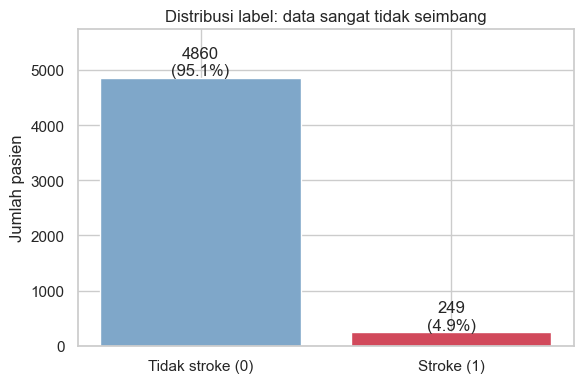

In [9]:
counts = df['stroke'].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(['Tidak stroke (0)', 'Stroke (1)'], counts.values, color=['#7fa7c9', '#d1495b'])
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 40, f'{v}\n({v / len(df):.1%})', ha='center')
ax.set_title('Distribusi label: data sangat tidak seimbang')
ax.set_ylabel('Jumlah pasien')
ax.set_ylim(0, counts.max() * 1.18)
plt.tight_layout(); plt.savefig('figures/01_target.png', dpi=150); plt.show()

**Insight 1:** hanya 4,9% pasien mengalami stroke. Model yang selalu menjawab "tidak stroke" sudah mendapat akurasi ~95% tanpa belajar apa pun. **Akurasi tidak bisa dipakai sebagai metrik utama.**

### 2. Fitur numerik vs stroke

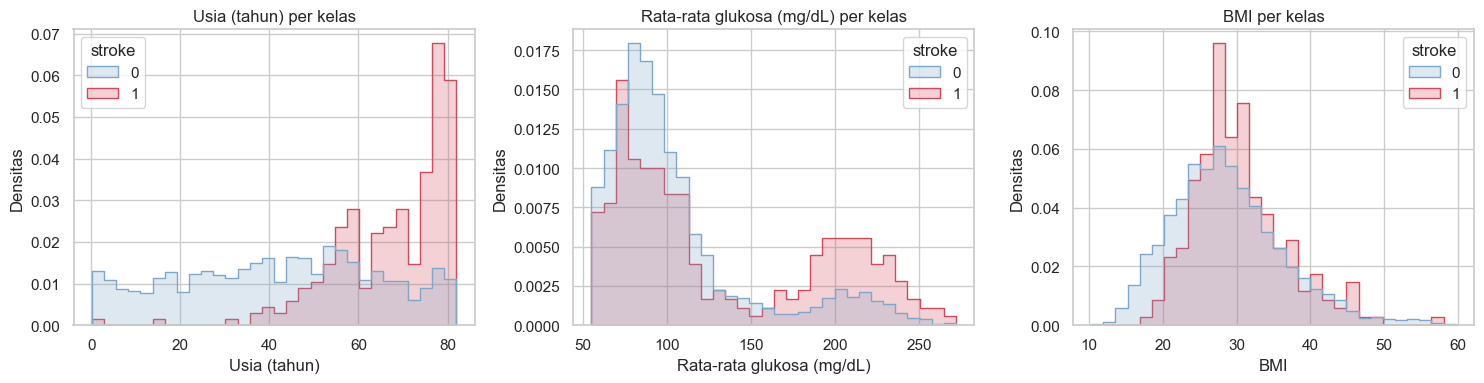

         age  avg_glucose_level   bmi
stroke                               
0       43.0               91.5  27.9
1       71.0              105.2  29.7


In [10]:
num_cols = ['age', 'avg_glucose_level', 'bmi']
titles = {'age': 'Usia (tahun)', 'avg_glucose_level': 'Rata-rata glukosa (mg/dL)', 'bmi': 'BMI'}
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.histplot(data=df, x=col, hue='stroke', stat='density', common_norm=False,
                 bins=30, element='step', palette=['#7fa7c9', '#d1495b'], ax=ax)
    ax.set_title(f'{titles[col]} per kelas'); ax.set_xlabel(titles[col]); ax.set_ylabel('Densitas')
plt.tight_layout(); plt.savefig('figures/02_numerik.png', dpi=150); plt.show()

print(df.groupby('stroke')[num_cols].median().round(1))

**Insight 2:** usia adalah pembeda paling jelas (median 71 vs 43 tahun). Glukosa pasien stroke punya "punuk kedua" di 180–250 mg/dL (kelompok diabetes), sehingga outlier glukosa memang perlu dipertahankan. Distribusi BMI kedua kelas hampir menumpuk, sehingga BMI diduga lemah.

### 3. Stroke rate per kelompok usia

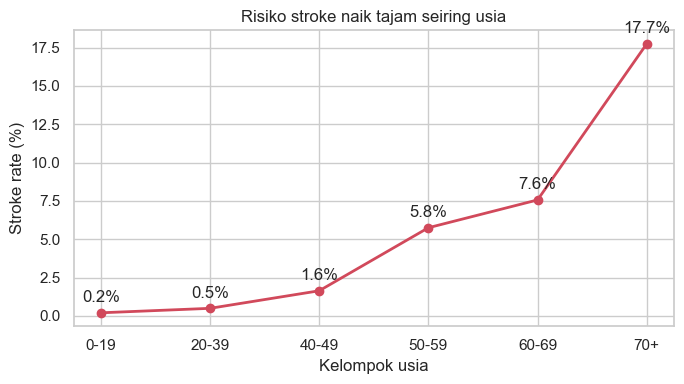

In [11]:
age_band = pd.cut(df['age'], bins=[0, 20, 40, 50, 60, 70, 83],
                  labels=['0-19', '20-39', '40-49', '50-59', '60-69', '70+'], right=False)
rate = df.groupby(age_band, observed=True)['stroke'].mean() * 100
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(rate.index.astype(str), rate.values, marker='o', color='#d1495b', lw=2)
for x, v in zip(rate.index.astype(str), rate.values):
    ax.text(x, v + 0.7, f'{v:.1f}%', ha='center')
ax.set_title('Risiko stroke naik tajam seiring usia')
ax.set_xlabel('Kelompok usia'); ax.set_ylabel('Stroke rate (%)')
plt.tight_layout(); plt.savefig('figures/03_usia.png', dpi=150); plt.show()

**Insight 3:** stroke rate naik dari 0,2% (usia < 20) ke 18% (usia ≥ 70), hampir 100 kali lipat. Kenaikannya tidak linear, tapi monoton, sehingga logistic regression masih bisa menangkapnya lewat koefisien usia.

### 4. Fitur kategorikal dan biner vs stroke
Untuk fitur kategorikal, yang dibandingkan adalah **stroke rate per kategori**, bukan korelasi antar kolom crosstab.

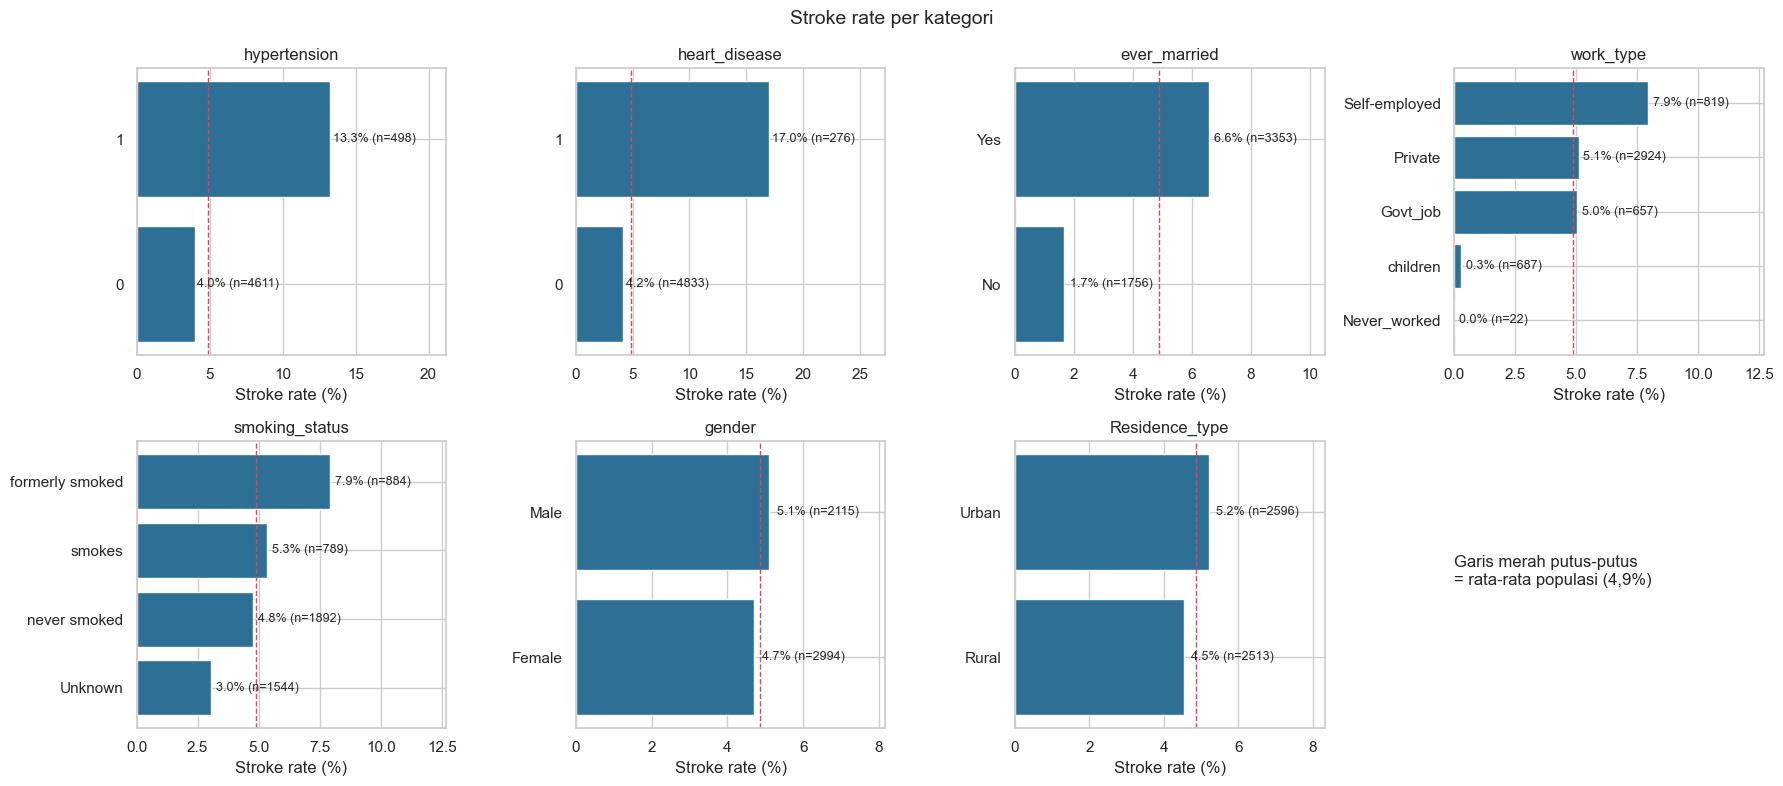

In [12]:
cat_cols = ['hypertension', 'heart_disease', 'ever_married', 'work_type',
            'smoking_status', 'gender', 'Residence_type']
base = df['stroke'].mean() * 100
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), cat_cols):
    r = (df.groupby(col)['stroke'].mean() * 100).sort_values()
    n = df[col].value_counts()
    ax.barh(r.index.astype(str), r.values, color='#2e6f95')
    ax.axvline(base, color='#d1495b', ls='--', lw=1)
    for i, (k, v) in enumerate(r.items()):
        ax.text(v + 0.2, i, f'{v:.1f}% (n={n[k]})', va='center', fontsize=9)
    ax.set_title(col); ax.set_xlabel('Stroke rate (%)'); ax.set_xlim(0, r.max() * 1.6)
axes.ravel()[-1].axis('off')
axes.ravel()[-1].text(0, 0.5, 'Garis merah putus-putus\n= rata-rata populasi (4,9%)', fontsize=12)
plt.suptitle('Stroke rate per kategori', fontsize=14)
plt.tight_layout(); plt.savefig('figures/04_kategorikal.png', dpi=150); plt.show()

**Insight 4:**
- `heart_disease` (17,0% vs 4,2%) dan `hypertension` (13,3% vs 4,0%) meningkatkan risiko sekitar 3–4 kali lipat.
- `ever_married` dan `work_type` terlihat sangat berpengaruh (menikah 6,6% vs belum 1,7%; children 0,3%). **Tetapi** ini perlu dicek apakah efek asli atau efek usia (lihat bagian 5).
- `smoking_status`: *formerly smoked* paling tinggi (7,9%), *Unknown* paling rendah (3,0%) karena didominasi anak-anak.
- `gender` dan `Residence_type` nyaris sama dengan rata-rata populasi, jadi pengaruhnya kecil.

### 5. Cek confounding: apakah `ever_married` dan `work_type` hanya "wakil" usia?

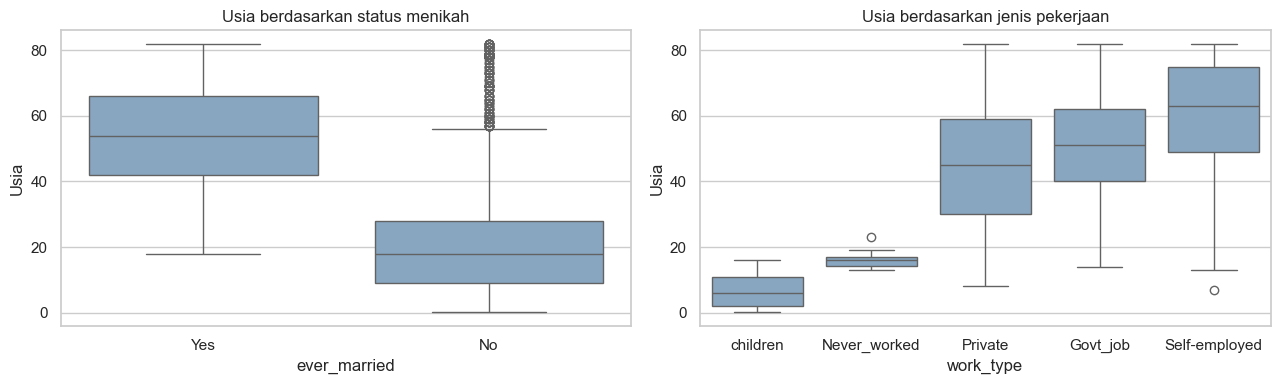

Median usia per status merokok: {'Unknown': 23.0, 'formerly smoked': 57.0, 'never smoked': 47.0, 'smokes': 47.0}

Stroke rate KHUSUS pasien usia >= 60 tahun:
  ever_married: {'No': '19.6% (n=107)', 'Yes': '12.6% (n=1269)'}
  smoking_status: {'Unknown': '11.9% (n=260)', 'formerly smoked': '13.9% (n=388)', 'never smoked': '13.2% (n=537)', 'smokes': '13.1% (n=191)'}


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=df, x='ever_married', y='age', ax=axes[0], color='#7fa7c9')
axes[0].set_title('Usia berdasarkan status menikah'); axes[0].set_ylabel('Usia')
order = df.groupby('work_type')['age'].median().sort_values().index
sns.boxplot(data=df, x='work_type', y='age', order=order, ax=axes[1], color='#7fa7c9')
axes[1].set_title('Usia berdasarkan jenis pekerjaan'); axes[1].set_ylabel('Usia')
plt.tight_layout(); plt.savefig('figures/05_confounding.png', dpi=150); plt.show()

older = df[df['age'] >= 60]
print('Median usia per status merokok:', df.groupby('smoking_status')['age'].median().to_dict())
print('\nStroke rate KHUSUS pasien usia >= 60 tahun:')
for col in ['ever_married', 'smoking_status']:
    t = older.groupby(col)['stroke'].agg(['mean', 'count'])
    print(f'  {col}:', {k: f"{v['mean']:.1%} (n={int(v['count'])})" for k, v in t.iterrows()})

**Insight 5 (penting):** kelompok "sudah menikah", "Self-employed", dan "formerly smoked" jauh lebih tua (median usia *formerly smoked* 57 tahun vs *never smoked* 47 tahun). Setelah usia dikendalikan (hanya pasien ≥ 60 tahun):
- efek `ever_married` **berbalik arah** (belum menikah 19,6% vs menikah 12,6%; jumlah belum menikah kecil, n=107)
- stroke rate semua kategori `smoking_status` hampir sama (11,9%–13,9%)

Artinya perbedaan besar yang terlihat di grafik bagian 4 sebagian besar adalah **efek usia yang menumpang** (*confounding*). Di dataset ini, status merokok ternyata **tidak** membawa informasi tambahan setelah usia diketahui. Ini bukan berarti merokok tidak berbahaya secara medis; kemungkinan besar karena data merokok di dataset ini kasar (self-report, 30% *Unknown*). Hipotesis ini diuji secara kuantitatif di Modul C.

### 6. Korelasi fitur numerik dan biner

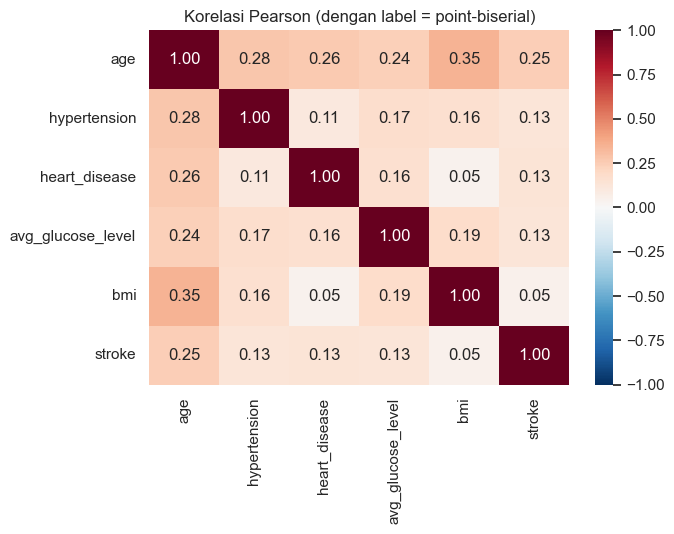

In [14]:
corr_df = df[['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi', 'stroke']]
plt.figure(figsize=(7, 5.5))
sns.heatmap(corr_df.corr(), annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1)
plt.title('Korelasi Pearson (dengan label = point-biserial)')
plt.tight_layout(); plt.savefig('figures/06_korelasi.png', dpi=150); plt.show()

**Insight 6:** semua korelasi dengan `stroke` lemah (≤ 0,25). Usia tertinggi (0,25), hipertensi, penyakit jantung, dan glukosa sekitar 0,13, BMI terendah (0,05). Korelasi lemah wajar untuk label yang langka dan **tidak berarti fitur tidak berguna**; korelasi Pearson juga hanya menangkap hubungan linear.

## Ringkasan Modul A
1. Label `stroke` sangat tidak seimbang (4,9%) → metrik utama nanti **recall dan F1**, bukan akurasi.
2. Kandidat fitur kuat: usia, hipertensi, penyakit jantung, glukosa.
3. `ever_married`, `work_type`, dan `smoking_status` sebagian besar diwakili usia; `gender`, `Residence_type`, dan `bmi` lemah.
4. BMI kosong **tidak di-drop**, karena menyimpan 16% kasus stroke.

---
# MODUL B — Klasifikasi
## B.1 Split data manual: stratified 70 / 15 / 15

**Kenapa diacak?** Urutan baris di file tidak acak (semua kasus stroke ada di baris-baris awal). Tanpa pengacakan, data uji bisa berisi kelas yang sama sekali berbeda dari data latih.

**Kenapa stratified?** Hanya ada 249 kasus stroke. Pengacakan biasa bisa membuat proporsi stroke di data uji melenceng jauh dari 4,9%. Stratified split mengacak kelas 0 dan kelas 1 secara terpisah, lalu membaginya dengan rasio yang sama.

**Kenapa ada data validasi?** Modul C meminta perbaikan model (class weight, pemilihan fitur, threshold). Jika perbaikan dipilih berdasarkan data uji, nilai uji menjadi terlalu optimis. Data validasi dipakai untuk memilih, data uji hanya untuk penilaian akhir.

**Kenapa 70/15/15?** Kompromi: data latih cukup besar untuk belajar, dan validasi maupun uji masing-masing tetap memiliki sekitar 37 kasus stroke.

In [15]:
def stratified_split(y, ratios=(0.70, 0.15, 0.15), seed=42):
    """Bagi indeks per kelas dengan rasio yang sama. Mengembalikan (idx_train, idx_val, idx_test)."""
    r = np.random.default_rng(seed)
    parts = [[], [], []]
    for cls in np.unique(y):
        idx = r.permutation(np.where(y == cls)[0])
        n_tr = int(round(ratios[0] * len(idx)))
        n_va = int(round(ratios[1] * len(idx)))
        parts[0].append(idx[:n_tr])
        parts[1].append(idx[n_tr:n_tr + n_va])
        parts[2].append(idx[n_tr + n_va:])
    return [r.permutation(np.concatenate(p)) for p in parts]

idx_tr, idx_va, idx_te = stratified_split(df['stroke'].values, seed=SEED)
train_df, val_df, test_df = df.iloc[idx_tr].copy(), df.iloc[idx_va].copy(), df.iloc[idx_te].copy()

assert len(set(idx_tr) & set(idx_va)) == 0 and len(set(idx_tr) & set(idx_te)) == 0 and len(set(idx_va) & set(idx_te)) == 0
for name, d in [('Train', train_df), ('Val', val_df), ('Test', test_df)]:
    print(f'{name:5s}: {len(d):5d} baris | stroke = {d["stroke"].sum():3d} ({d["stroke"].mean():.2%})')

Train:  3576 baris | stroke = 174 (4.87%)
Val  :   766 baris | stroke =  37 (4.83%)
Test :   767 baris | stroke =  38 (4.95%)


## B.2 Preprocessing (fit di train, transform di semua split)

| Langkah | Detail | Dihitung dari |
|---|---|---|
| Imputasi BMI | median BMI per kelompok usia | train |
| Encoding biner | `gender`→`is_male`, `ever_married`→1/0, `Residence_type`→`is_urban` | aturan tetap |
| One-hot encoding | `work_type`, `smoking_status` (kategori pertama jadi baseline/dibuang) | kategori dari train |
| Normalisasi z-score | `age`, `avg_glucose_level`, `bmi` | mean dan std train |

**Kenapa one-hot, bukan label encoding 0,1,2,3?** Label encoding memaksa urutan dan jarak yang sama (*Unknown* < *never* < *formerly* < *smokes*), padahal data menunjukkan *formerly smoked* lebih berisiko daripada *smokes*. One-hot memberi setiap kategori bobotnya sendiri.

**Kenapa satu kategori dibuang?** Jika semua kolom one-hot dipakai, jumlahnya selalu 1 dan identik dengan bias (*dummy variable trap*). Kategori yang dibuang menjadi pembanding: bobot kolom lain dibaca sebagai "lebih atau kurang berisiko dibanding baseline".

**Kenapa z-score?** Gradient descent memakai satu learning rate untuk semua bobot. Jika usia (0–82) dan glukosa (55–272) tidak diskalakan, gradiennya timpang dan training lambat atau zig-zag. Setelah z-score, besar koefisien juga bisa dibandingkan antar fitur. Z-score dipilih daripada min-max karena glukosa punya outlier yang dipertahankan; min-max akan "menekan" mayoritas data ke rentang sempit.

In [16]:
AGE_BINS = [0, 13, 18, 30, 45, 60, 200]
AGE_LABELS = ['0-12', '13-17', '18-29', '30-44', '45-59', '60+']

class Preprocessor:
    """Semua parameter dipelajari dari data latih saja (anti data leakage)."""
    NUM = ['age', 'avg_glucose_level', 'bmi']
    ONEHOT = {'work_type': 'Private', 'smoking_status': 'never smoked'}   # nilai = kategori baseline

    def fit(self, d):
        grp = pd.cut(d['age'], bins=AGE_BINS, labels=AGE_LABELS, right=False)
        self.bmi_median = d.groupby(grp, observed=False)['bmi'].median().to_dict()
        d = self._impute(d)
        self.mean = d[self.NUM].mean().to_dict()
        self.std = d[self.NUM].std().to_dict()
        self.categories = {c: sorted(v for v in d[c].unique() if v != base)
                           for c, base in self.ONEHOT.items()}
        return self

    def _impute(self, d):
        d = d.copy()
        grp = pd.cut(d['age'], bins=AGE_BINS, labels=AGE_LABELS, right=False).astype(str)
        d['bmi'] = d['bmi'].fillna(grp.map(self.bmi_median))
        return d

    def transform(self, d):
        d = self._impute(d)
        X = pd.DataFrame(index=d.index)
        for c in self.NUM:
            X[c] = (d[c] - self.mean[c]) / self.std[c]
        X['hypertension'] = d['hypertension']
        X['heart_disease'] = d['heart_disease']
        X['is_male'] = (d['gender'] == 'Male').astype(int)
        X['ever_married'] = (d['ever_married'] == 'Yes').astype(int)
        X['is_urban'] = (d['Residence_type'] == 'Urban').astype(int)
        for c, cats in self.categories.items():
            for v in cats:
                X[f'{c}={v}'] = (d[c] == v).astype(int)
        return X.astype(float)

prep = Preprocessor().fit(train_df)
X_train_df, X_val_df, X_test_df = prep.transform(train_df), prep.transform(val_df), prep.transform(test_df)
y_train, y_val, y_test = (d['stroke'].values.astype(float) for d in (train_df, val_df, test_df))
FEATURES_ALL = list(X_train_df.columns)

print('Median BMI per kelompok usia (dari train):', {k: round(v, 1) for k, v in prep.bmi_median.items()})
print('Sisa NaN setelah transform:', int(X_train_df.isna().sum().sum() + X_val_df.isna().sum().sum() + X_test_df.isna().sum().sum()))
print('Jumlah fitur:', len(FEATURES_ALL))
X_train_df.head()

Median BMI per kelompok usia (dari train): {'0-12': 18.6, '13-17': 23.9, '18-29': 26.5, '30-44': 29.8, '45-59': 30.3, '60+': 29.4}
Sisa NaN setelah transform: 0
Jumlah fitur: 15


,age,avg_glucose_level,bmi,hypertension,heart_disease,is_male,ever_married,is_urban,work_type=Govt_job,work_type=Never_worked,work_type=Self-employed,work_type=children,smoking_status=Unknown,smoking_status=formerly smoked,smoking_status=smokes
774,-0.535635,-1.117478,0.494420,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
3280,-1.683740,-0.709851,-1.564601,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0
1574,1.363154,-0.875962,0.750115,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2306,-0.403161,-0.419376,1.288422,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2691,0.082575,-0.053714,0.494420,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [17]:
print('Cek normalisasi di train (harus mean ~0, std ~1):')
print(X_train_df[Preprocessor.NUM].agg(['mean', 'std']).round(3))

Cek normalisasi di train (harus mean ~0, std ~1):
      age  avg_glucose_level  bmi
mean -0.0                0.0  0.0
std   1.0                1.0  1.0


## B.3 Logistic regression dari nol

**1. Kombinasi linear (logit):**  $z = \mathbf{w}^\top\mathbf{x} + b$

**2. Sigmoid**, mengubah $z$ menjadi probabilitas 0–1: $\hat{p} = \sigma(z) = \dfrac{1}{1 + e^{-z}}$

**3. Loss Binary Cross-Entropy** (dengan bobot sampel $s_i$, default semua 1):
$$L = -\frac{1}{\sum s_i}\sum_i s_i\left[y_i\log\hat{p}_i + (1-y_i)\log(1-\hat{p}_i)\right]$$
Loss besar ketika model yakin tapi salah (mis. $\hat p = 0.01$ padahal $y=1$ → $-\log 0.01 = 4.6$).

**4. Gradien** (turunan sigmoid dan log saling menyederhanakan menjadi bentuk yang rapi):
$$\frac{\partial L}{\partial \mathbf{w}} = \frac{1}{\sum s_i} X^\top\left[s \odot (\hat{\mathbf{p}} - \mathbf{y})\right], \qquad \frac{\partial L}{\partial b} = \frac{1}{\sum s_i}\sum_i s_i(\hat{p}_i - y_i)$$

**5. Gradient descent:** $\mathbf{w} \leftarrow \mathbf{w} - \eta\,\partial L/\partial\mathbf{w}$, diulang sebanyak `epochs`.

Detail implementasi: `np.clip` pada $z$ mencegah overflow `np.exp`, dan pada $\hat p$ mencegah `log(0)`.

In [18]:
class LogisticRegressionScratch:
    def __init__(self, lr=0.1, epochs=2000, class_weight=None):
        self.lr, self.epochs, self.class_weight = lr, epochs, class_weight

    @staticmethod
    def sigmoid(z):
        return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))

    def _sample_weight(self, y):
        if self.class_weight is None:
            return np.ones_like(y)
        return np.where(y == 1, self.class_weight[1], self.class_weight[0])

    def loss(self, X, y, w=None, b=None):
        w = self.w if w is None else w
        b = self.b if b is None else b
        p = np.clip(self.sigmoid(X @ w + b), 1e-12, 1 - 1e-12)
        s = self._sample_weight(y)
        return -np.sum(s * (y * np.log(p) + (1 - y) * np.log(1 - p))) / s.sum()

    def gradient(self, X, y, w, b):
        s = self._sample_weight(y)
        err = s * (self.sigmoid(X @ w + b) - y)
        return X.T @ err / s.sum(), err.sum() / s.sum()

    def fit(self, X, y, X_val=None, y_val=None):
        self.w, self.b = np.zeros(X.shape[1]), 0.0
        self.history = {'train': [], 'val': []}
        for _ in range(self.epochs):
            self.history['train'].append(self.loss(X, y))
            if X_val is not None:
                self.history['val'].append(self.loss(X_val, y_val))
            dw, db = self.gradient(X, y, self.w, self.b)
            self.w -= self.lr * dw
            self.b -= self.lr * db
        return self

    def predict_proba(self, X):
        return self.sigmoid(X @ self.w + self.b)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

## B.4 Membuktikan training berjalan benar
Tiga bukti: (1) loss awal sesuai teori, (2) gradien analitik sama dengan gradien numerik, (3) loss turun dan stabil.

In [19]:
Xtr, Xva, Xte = X_train_df.values, X_val_df.values, X_test_df.values

# Bukti 1: dengan w=0 dan b=0, semua prediksi 0.5 -> loss harus ln(2)
m = LogisticRegressionScratch()
print(f'Loss awal = {m.loss(Xtr, y_train, np.zeros(Xtr.shape[1]), 0.0):.4f} | ln 2 = {np.log(2):.4f}')

# Bukti 2: gradient check dengan beda hingga (finite difference) pada bobot acak
w0, b0, eps = rng.normal(0, 0.1, Xtr.shape[1]), 0.1, 1e-5
dw, _ = m.gradient(Xtr, y_train, w0, b0)
num = np.array([(m.loss(Xtr, y_train, w0 + eps * e, b0) - m.loss(Xtr, y_train, w0 - eps * e, b0)) / (2 * eps)
                for e in np.eye(len(w0))])
print(f'Selisih maksimum gradien analitik vs numerik: {np.max(np.abs(dw - num)):.2e}  (harus sangat kecil)')

Loss awal = 0.6931 | ln 2 = 0.6931
Selisih maksimum gradien analitik vs numerik: 9.96e-12  (harus sangat kecil)


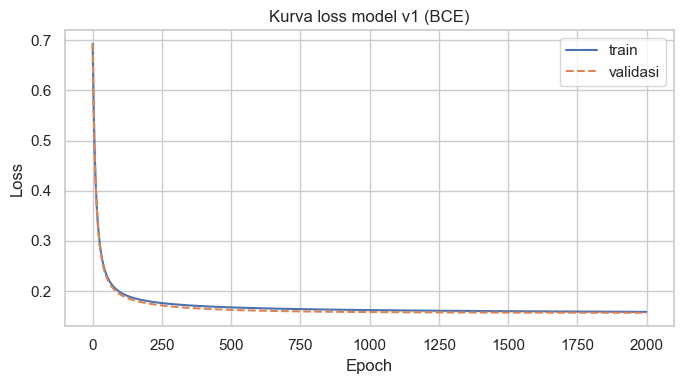

Loss train: 0.6931 -> 0.1585
Loss val  : 0.6931 -> 0.1566


In [20]:
# Model v1 (baseline): semua fitur, tanpa class weight
model_v1 = LogisticRegressionScratch(lr=0.1, epochs=2000).fit(Xtr, y_train, Xva, y_val)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(model_v1.history['train'], label='train')
ax.plot(model_v1.history['val'], label='validasi', ls='--')
ax.set_title('Kurva loss model v1 (BCE)'); ax.set_xlabel('Epoch'); ax.set_ylabel('Loss')
ax.legend(); plt.tight_layout(); plt.savefig('figures/07_loss_v1.png', dpi=150); plt.show()
print(f"Loss train: {model_v1.history['train'][0]:.4f} -> {model_v1.history['train'][-1]:.4f}")
print(f"Loss val  : {model_v1.history['val'][0]:.4f} -> {model_v1.history['val'][-1]:.4f}")

Loss turun dari 0,693 (= ln 2, tebakan acak) lalu mendatar, dan loss validasi mengikuti loss latih tanpa naik kembali. Artinya training konvergen dan tidak ada tanda overfitting. Model linear dengan 15 fitur dan 3.500 data memang kecil kemungkinannya overfit.

---
# MODUL C — Evaluasi Model
## C.1 Confusion matrix dan metrik tanpa library

|  | Prediksi stroke | Prediksi tidak |
|---|---|---|
| **Aktual stroke** | TP | FN (**terlewat**, paling berbahaya) |
| **Aktual tidak** | FP (alarm palsu) | TN |

- **Recall** = TP / (TP + FN): dari semua pasien stroke, berapa yang tertangkap
- **Precision** = TP / (TP + FP): dari yang diberi alarm, berapa yang benar stroke
- **F1** = rata-rata harmonik precision dan recall
- **AUC (ROC)**: peluang model memberi skor lebih tinggi ke pasien stroke daripada pasien sehat; tidak bergantung threshold

**Pilihan metrik:** ini alat **skrining**. FN (pasien berisiko dinyatakan aman) jauh lebih mahal daripada FP (pasien sehat diminta cek lanjutan). Karena itu **recall menjadi metrik utama**, dengan precision dan F1 sebagai penyeimbang agar model tidak asal memberi alarm ke semua orang. AUC dipakai untuk membandingkan model sebelum memilih threshold.

In [21]:
def confusion_matrix(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true).astype(int), np.asarray(y_pred).astype(int)
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    return tp, fn, fp, tn

def safe_div(a, b):
    return a / b if b else 0.0

def roc_auc(y_true, score):
    """AUC via statistik Mann-Whitney: rata-rata peringkat skor kelas positif."""
    ranks = pd.Series(score).rank().values          # rank rata-rata untuk nilai yang sama
    pos = np.asarray(y_true) == 1
    n_pos, n_neg = pos.sum(), (~pos).sum()
    return (ranks[pos].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)

def evaluate(y_true, proba, threshold=0.5):
    tp, fn, fp, tn = confusion_matrix(y_true, proba >= threshold)
    prec, rec = safe_div(tp, tp + fp), safe_div(tp, tp + fn)
    return {'threshold': threshold, 'TP': tp, 'FN': fn, 'FP': fp, 'TN': tn,
            'accuracy': (tp + tn) / (tp + fn + fp + tn), 'precision': prec, 'recall': rec,
            'specificity': safe_div(tn, tn + fp), 'f1': safe_div(2 * prec * rec, prec + rec),
            'auc': float(roc_auc(y_true, proba))}

def plot_cm(ax, y_true, proba, threshold, title):
    tp, fn, fp, tn = confusion_matrix(y_true, proba >= threshold)
    cm = np.array([[tp, fn], [fp, tn]])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Prediksi stroke', 'Prediksi tidak'],
                yticklabels=['Aktual stroke', 'Aktual tidak'], annot_kws={'size': 13})
    ax.set_title(title)

# Uji kecil fungsi metrik dengan contoh yang bisa dihitung manual
assert confusion_matrix([1, 1, 0, 0, 1], [1, 0, 0, 1, 1]) == (2, 1, 1, 1)
print('Fungsi metrik lolos uji contoh manual.')

Fungsi metrik lolos uji contoh manual.


## C.2 Evaluasi model v1 (baseline) di data validasi

In [22]:
p_val_v1 = model_v1.predict_proba(Xva)
res_v1 = evaluate(y_val, p_val_v1, 0.5)
baseline_acc = 1 - y_val.mean()
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in res_v1.items()})
print(f'\nPembanding: model bodoh "selalu tidak stroke" -> akurasi {baseline_acc:.3f}, recall 0')

{'threshold': 0.5, 'TP': 0, 'FN': 37, 'FP': 0, 'TN': 729, 'accuracy': 0.952, 'precision': 0.0, 'recall': 0.0, 'specificity': 1.0, 'f1': 0.0, 'auc': 0.842}

Pembanding: model bodoh "selalu tidak stroke" -> akurasi 0.952, recall 0


**Diagnosis:** akurasi v1 terlihat bagus (~95%), tetapi **recall 0**: tidak ada satu pun pasien stroke yang terdeteksi. Model v1 sama saja dengan menebak "tidak stroke" untuk semua orang. Sebenarnya AUC-nya cukup baik (~0,8), jadi model sudah bisa **mengurutkan** risiko, hanya saja probabilitasnya tidak pernah melewati 0,5 karena hanya 4,9% data latih yang positif.

Dua penyebab, dua perbaikan:
1. Loss didominasi kelas mayoritas → **class weight**
2. Threshold 0,5 tidak cocok untuk kasus langka → **tuning threshold** di data validasi

## C.3 Perbaikan 1: class weight
Bobot setiap kelas = $\dfrac{n_{total}}{2 \cdot n_{kelas}}$. Satu pasien stroke "bernilai" sekitar 10 pasien sehat dalam loss, sehingga kesalahan pada kelas langka tidak bisa diabaikan model.

In [23]:
n, n_pos = len(y_train), y_train.sum()
CLASS_WEIGHT = {0: float(n / (2 * (n - n_pos))), 1: float(n / (2 * n_pos))}
print('Class weight:', {k: round(v, 3) for k, v in CLASS_WEIGHT.items()})

model_v2 = LogisticRegressionScratch(lr=0.1, epochs=2000, class_weight=CLASS_WEIGHT).fit(Xtr, y_train, Xva, y_val)
res_v2 = evaluate(y_val, model_v2.predict_proba(Xva), 0.5)
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in res_v2.items()})

Class weight: {0: 0.526, 1: 10.276}
{'threshold': 0.5, 'TP': 29, 'FN': 8, 'FP': 199, 'TN': 530, 'accuracy': 0.73, 'precision': 0.127, 'recall': 0.784, 'specificity': 0.727, 'f1': 0.219, 'auc': 0.845}


## C.4 Perbaikan 2: pemilihan fitur berbasis bukti
Hipotesis dari Modul A: banyak fitur hanya "menumpang" pada usia. Tiga set fitur dibandingkan **di data validasi** dengan AUC (semua memakai class weight):

| Set | Isi | Input di GUI |
|---|---|---|
| A | semua 15 kolom | 10 |
| B | usia, glukosa, hipertensi, penyakit jantung, status merokok (pilihan awal Wiryateja) | 5 |
| C | usia, glukosa, hipertensi, penyakit jantung | 4 |

**Aturan keputusan (ditetapkan sebelum melihat hasil):** pilih set paling sederhana yang AUC validasinya tidak lebih dari 0,01 di bawah set terbaik. Model sederhana lebih mudah dijelaskan, inputnya lebih mudah didapat petugas, dan lebih kecil risikonya menangkap pola kebetulan.

In [24]:
FEATURE_SETS = {
    'A (15 kolom)': FEATURES_ALL,
    'B (5 input)': ['age', 'avg_glucose_level', 'hypertension', 'heart_disease',
                    'smoking_status=Unknown', 'smoking_status=formerly smoked', 'smoking_status=smokes'],
    'C (4 input)': ['age', 'avg_glucose_level', 'hypertension', 'heart_disease'],
}
fs_models, fs_rows = {}, []
for name, feats in FEATURE_SETS.items():
    idx = [FEATURES_ALL.index(f) for f in feats]
    m = LogisticRegressionScratch(lr=0.1, epochs=2000, class_weight=CLASS_WEIGHT).fit(Xtr[:, idx], y_train)
    fs_models[name] = (m, idx)
    fs_rows.append({'set': name, 'jumlah_kolom': len(feats), 'auc_val': roc_auc(y_val, m.predict_proba(Xva[:, idx]))})
fs_table = pd.DataFrame(fs_rows).set_index('set')
best_auc = fs_table['auc_val'].max()
eligible = fs_table[fs_table['auc_val'] >= best_auc - 0.01]
CHOSEN = eligible['jumlah_kolom'].idxmin()
print(fs_table.round(3))
print('\nSet terpilih:', CHOSEN)

m_b, idx_b = fs_models['B (5 input)']
print('\nKoefisien set B (cek kewajaran):')
print(pd.Series(m_b.w, index=FEATURE_SETS['B (5 input)']).round(3).to_string())

              jumlah_kolom  auc_val
set                                
A (15 kolom)            15    0.845
B (5 input)              7    0.852
C (4 input)              4    0.859

Set terpilih: C (4 input)

Koefisien set B (cek kewajaran):
age                               1.654
avg_glucose_level                 0.158
hypertension                      0.459
heart_disease                     0.415
smoking_status=Unknown            0.255
smoking_status=formerly smoked   -0.126
smoking_status=smokes             0.335


**Hasil:** AUC ketiga set berada dalam rentang 0,01–0,02, dan set paling sederhana (C, 4 input) justru sedikit lebih tinggi. Menambah fitur lemah hanya menambah noise. Set C terpilih.

Koefisien set B juga menunjukkan masalah: `smoking_status=formerly smoked` bernilai **negatif**, seolah pernah merokok menurunkan risiko stroke. Ini konsisten dengan Insight 5: setelah usia masuk ke model, status merokok tidak membawa informasi yang stabil. Jika tetap dipakai, GUI bisa menampilkan penjelasan yang menyesatkan bagi petugas kesehatan ("pernah merokok menurunkan risiko"). Jadi membuang status merokok di sini adalah keputusan **berbasis data dan keamanan pengguna**, bukan klaim medis bahwa merokok tidak berbahaya.

In [25]:
model_final, sel = fs_models[CHOSEN]
FEATURES_FINAL = FEATURE_SETS[CHOSEN]
print('Fitur model final:', FEATURES_FINAL)

Fitur model final: ['age', 'avg_glucose_level', 'hypertension', 'heart_disease']


## C.5 Perbaikan 3: memilih threshold di data validasi
Aturan operasional: **pilih threshold tertinggi yang masih menangkap minimal 80% pasien stroke di data validasi** (recall ≥ 0,80). Threshold lebih tinggi berarti alarm palsu lebih sedikit, jadi di antara threshold yang memenuhi target recall, yang tertinggi adalah yang paling efisien.

Catatan: threshold hasil tuning bisa saja jatuh dekat 0,5. Itu wajar, karena class weight sudah menggeser probabilitas. Yang dinilai bukan angkanya berbeda dari 0,5, melainkan bahwa threshold **dipilih dengan aturan yang jelas di data validasi**, bukan dipakai begitu saja sebagai default.

Threshold terpilih: 0.53
           recall  precision     f1   FP
threshold                               
0.30        0.973      0.103  0.186  315
0.40        0.919      0.119  0.211  252
0.50        0.838      0.133  0.230  202
0.53        0.811      0.138  0.235  188
0.60        0.703      0.159  0.259  138
0.70        0.568      0.172  0.264  101


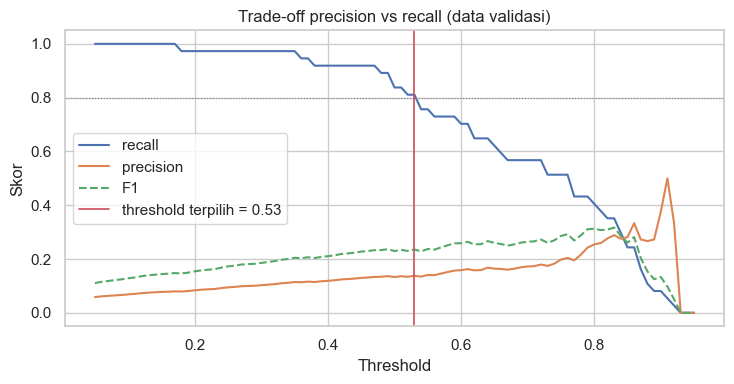

In [26]:
TARGET_RECALL = 0.80
p_val_final = model_final.predict_proba(Xva[:, sel])
grid = np.round(np.arange(0.05, 0.96, 0.01), 2)
curve = pd.DataFrame([evaluate(y_val, p_val_final, t) for t in grid])
ok = curve[curve['recall'] >= TARGET_RECALL]
BEST_T = float(ok['threshold'].max())
print(f'Threshold terpilih: {BEST_T}')
show_t = sorted({0.3, 0.4, 0.5, 0.6, 0.7, BEST_T})
print(curve.set_index('threshold').loc[show_t, ['recall', 'precision', 'f1', 'FP']].round(3))

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(curve['threshold'], curve['recall'], label='recall')
ax.plot(curve['threshold'], curve['precision'], label='precision')
ax.plot(curve['threshold'], curve['f1'], label='F1', ls='--')
ax.axhline(TARGET_RECALL, color='grey', lw=0.8, ls=':')
ax.axvline(BEST_T, color='#d1495b', lw=1.2, label=f'threshold terpilih = {BEST_T}')
ax.set_title('Trade-off precision vs recall (data validasi)'); ax.set_xlabel('Threshold'); ax.set_ylabel('Skor')
ax.legend(); plt.tight_layout(); plt.savefig('figures/08_threshold.png', dpi=150); plt.show()

## C.6 Evaluasi akhir di data uji (sekali saja): sebelum vs sesudah

,TP,FN,FP,TN,accuracy,precision,recall,f1,auc
"v1 baseline (15 kolom, t=0.5)",0.0,38.0,0.0,729.0,0.950,0.000,0.000,0.000,0.838
"v2 + class weight (15 kolom, t=0.5)",33.0,5.0,198.0,531.0,0.735,0.143,0.868,0.245,0.848
FINAL: class weight + 4 input + t=0.53,33.0,5.0,180.0,549.0,0.759,0.155,0.868,0.263,0.850


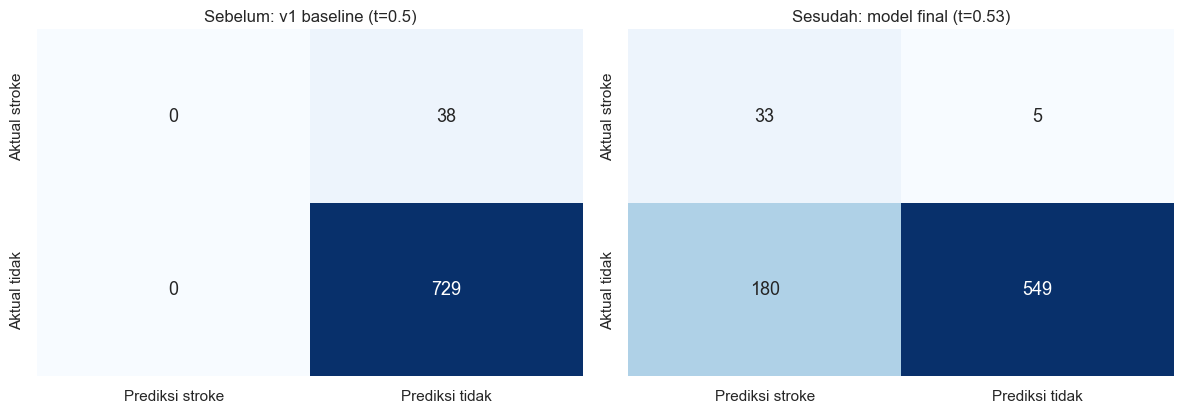

In [27]:
p_test_v1 = model_v1.predict_proba(Xte)
p_test_final = model_final.predict_proba(Xte[:, sel])
FINAL_NAME = f'FINAL: class weight + {len(FEATURES_FINAL)} input + t={BEST_T}'
rows = {
    'v1 baseline (15 kolom, t=0.5)': evaluate(y_test, p_test_v1, 0.5),
    'v2 + class weight (15 kolom, t=0.5)': evaluate(y_test, model_v2.predict_proba(Xte), 0.5),
    FINAL_NAME: evaluate(y_test, p_test_final, BEST_T),
}
comparison = pd.DataFrame(rows).T[['TP', 'FN', 'FP', 'TN', 'accuracy', 'precision', 'recall', 'f1', 'auc']]
display(comparison.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
plot_cm(axes[0], y_test, p_test_v1, 0.5, 'Sebelum: v1 baseline (t=0.5)')
plot_cm(axes[1], y_test, p_test_final, BEST_T, f'Sesudah: model final (t={BEST_T})')
plt.tight_layout(); plt.savefig('figures/09_cm_before_after.png', dpi=150); plt.show()

In [28]:
final_res = rows[FINAL_NAME]
base_rate = y_test.mean()
print(f'Pasien stroke tertangkap : {final_res["TP"]} dari {final_res["TP"] + final_res["FN"]} ({final_res["recall"]:.0%})')
print(f'Precision alarm          : {final_res["precision"]:.1%}  vs stroke rate populasi {base_rate:.1%}')
print(f'Lift                     : {final_res["precision"] / base_rate:.1f}x lebih tepat daripada memeriksa pasien secara acak')
print(f'Pasien yang perlu dicek lanjut: {final_res["TP"] + final_res["FP"]} dari {len(y_test)} ({(final_res["TP"] + final_res["FP"]) / len(y_test):.0%})')

Pasien stroke tertangkap : 33 dari 38 (87%)
Precision alarm          : 15.5%  vs stroke rate populasi 5.0%
Lift                     : 3.1x lebih tepat daripada memeriksa pasien secara acak
Pasien yang perlu dicek lanjut: 213 dari 767 (28%)


**Interpretasi:**
- Sebelum perbaikan, model tidak menangkap satu pun pasien stroke. Sesudah perbaikan, model final menangkap sebagian besar pasien stroke di data uji, hanya dengan 4 input.
- Model final menyamai recall v2 (15 kolom) dengan alarm palsu lebih sedikit. Ini konsisten dengan keputusan C.4: 11 kolom tambahan tidak memberi nilai.
- Akurasi **turun**, dan itu disengaja: model sekarang berani memberi alarm. Penurunan akurasi pada kasus tidak seimbang bukan tanda model memburuk.
- Konsekuensinya, sekitar 28% pasien diminta pemeriksaan lanjutan. Precision terlihat rendah, tetapi bandingkan dengan stroke rate populasi: pasien yang diberi alarm oleh model beberapa kali lebih mungkin benar-benar stroke daripada pasien yang dipilih acak. Untuk alat skrining (bukan diagnosis), ini trade-off yang wajar: lebih baik banyak pasien diminta cek lanjutan daripada pasien berisiko terlewat.
- Nilai metrik pada data uji dihitung dari sekitar 38 kasus positif, jadi angka recall bisa bergeser beberapa poin jika data uji diganti. Angkanya perlu dibaca sebagai perkiraan, bukan kepastian.

## C.7 Membaca model: koefisien dan odds ratio

In [29]:
coef = pd.DataFrame({'fitur': FEATURES_FINAL, 'koefisien': model_final.w, 'odds_ratio': np.exp(model_final.w)})
coef = coef.sort_values('koefisien', ascending=False).reset_index(drop=True)
display(coef.round(3))
print(f"Contoh: setiap kenaikan usia 1 standar deviasi ({prep.std['age']:.1f} tahun), odds stroke dikali {np.exp(model_final.w[FEATURES_FINAL.index('age')]):.2f}")

,fitur,koefisien,odds_ratio
0,age,1.616,5.033
1,heart_disease,0.461,1.586
2,hypertension,0.436,1.546
3,avg_glucose_level,0.157,1.170


Contoh: setiap kenaikan usia 1 standar deviasi (22.6 tahun), odds stroke dikali 5.03


Usia mendominasi. Hipertensi dan penyakit jantung masing-masing menaikkan odds sekitar 1,5–1,6 kali, dan glukosa memberi kontribusi positif yang lebih kecil. Semua koefisien positif dan searah dengan temuan EDA maupun pengetahuan medis, sehingga penjelasan faktor risiko di GUI aman dibaca petugas kesehatan.

Catatan cara membaca: koefisien usia dan glukosa berlaku per 1 standar deviasi (karena z-score), sedangkan koefisien hipertensi dan penyakit jantung berlaku untuk perubahan 0 → 1.

## C.8 Menyimpan model untuk Modul D
Model disimpan sebagai JSON (bukan pickle): bisa dibaca manusia, aman dibuka, dan memuat semua yang dibutuhkan GUI untuk memproses input mentah dengan cara yang **persis sama** seperti saat training.

In [30]:
model_artifact = {
    'name': 'StrokeCheck - Logistic Regression (scratch)',
    'features': FEATURES_FINAL,
    'weights': [float(v) for v in model_final.w],
    'bias': float(model_final.b),
    'threshold': BEST_T,
    'scaler': {c: {'mean': prep.mean[c], 'std': prep.std[c]} for c in ['age', 'avg_glucose_level']},
    'training_range': {'age': [float(train_df['age'].min()), float(train_df['age'].max())],
                       'avg_glucose_level': [float(train_df['avg_glucose_level'].min()),
                                             float(train_df['avg_glucose_level'].max())]},
    'population_stroke_rate': float(df['stroke'].mean()),
    'test_metrics': {k: (round(v, 4) if isinstance(v, float) else v) for k, v in final_res.items()},
    'hyperparameters': {'lr': 0.1, 'epochs': 2000, 'class_weight': CLASS_WEIGHT, 'split': '70/15/15 stratified, seed 42'},
}
with open('model_stroke.json', 'w') as f:
    json.dump(model_artifact, f, indent=2)

# Sanity check: muat ulang dan pastikan prediksi identik
with open('model_stroke.json') as f:
    loaded = json.load(f)
p_reload = LogisticRegressionScratch.sigmoid(Xte[:, sel] @ np.array(loaded['weights']) + loaded['bias'])
print('Model tersimpan. Prediksi setelah dimuat ulang identik:', np.allclose(p_reload, p_test_final))

Model tersimpan. Prediksi setelah dimuat ulang identik: True


## C.9 Konsistensi dengan GUI (Modul D)
GUI di `gui_stroke.py` memproses **input mentah** (usia dalam tahun, glukosa dalam mg/dL, Ya/Tidak). Uji di bawah memastikan fungsi prediksi di GUI menghasilkan probabilitas yang sama dengan pipeline notebook.

In [31]:
from gui_stroke import load_model, predict

gui_model = load_model('model_stroke.json')
gui_probs = []
for _, r in test_df.iterrows():
    clean = {'age': r['age'], 'avg_glucose_level': r['avg_glucose_level'],
             'hypertension': int(r['hypertension']), 'heart_disease': int(r['heart_disease'])}
    gui_probs.append(predict(gui_model, clean)['probability'])
print('Prediksi GUI == prediksi notebook untuk seluruh data uji:', np.allclose(gui_probs, p_test_final))

ModuleNotFoundError: No module named 'gui_stroke'

## Keterbatasan dan langkah berikutnya
1. **Bukan alat diagnosis.** Dataset ini tidak memuat faktor penting seperti kolesterol, riwayat keluarga, aktivitas fisik, atau tekanan darah numerik. Status merokok tidak dipakai karena datanya tidak informatif di dataset ini, bukan karena merokok aman. Model hanya menyaring siapa yang perlu dicek lebih lanjut.
2. **Data uji kecil untuk kelas positif** (~38 kasus). Estimasi yang lebih stabil bisa didapat dengan cross-validation manual.
3. **Hubungan usia tidak linear.** Fitur tambahan seperti `age²` atau kelompok usia bisa dicoba, dibandingkan lewat AUC validasi.
4. **Validitas eksternal.** Data berasal dari satu sumber publik (bukan populasi Indonesia), sehingga threshold perlu dikalibrasi ulang sebelum dipakai di puskesmas.
5. **Skor bukan peluang.** Karena dilatih dengan class weight, output sigmoid model final sengaja "digeser" ke atas dan tidak lagi sama dengan peluang stroke sebenarnya (tidak terkalibrasi). Skor hanya boleh dipakai untuk mengurutkan risiko dan dibandingkan dengan threshold. Karena itu GUI menampilkan "skor risiko 0–100", bukan "peluang stroke X%".
6. **Pilihan threshold** bergantung pada kapasitas fasilitas: jika fasilitas hanya mampu memeriksa sedikit pasien, threshold bisa dinaikkan dengan konsekuensi recall turun.